# Assignment No. 03:
  ## Classifying Heartbeats from ECG Signals
  ### **Team Members:**
1. **Rizwana Mubarak** — Roll No: **23F-6055**  
2. **Abdul Rehman** — Roll No: **23F-6075**

### Strict Library Constraints:
- **Allowed**:
  - torch,
  - tensors and automatic differentiation(loss.backward())
  - nn.Module, nn.Parameter, nn.ParameterList
  - torch.logsumexp,
  - torch.softmax (for reporting probabilities only)

### Environment Setup

In [38]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

# Ensure results directory exists for figures and checkpoints
results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)
print(f"Results directory: {results_dir.resolve()}")

Results directory: /content/results


In [14]:
import os
import shutil
from pathlib import Path

# Move the file
results_dir = Path("/content/data")
results_dir.mkdir(parents=True, exist_ok=True)

In [18]:
results_dir = Path("/content/data")
results_dir.mkdir(parents=True, exist_ok=True)

if results_dir.exists():
    source_path_1 = '/content/mitbih_test.csv'
    source_path_2 = '/content/mitbih_train.csv'
    destination_path = '/content/data/mitbih_test.csv'
    destination_path_2 = '/content/data/mitbih_train.csv'

    if os.path.exists(source_path_1) and os.path.exists(source_path_2):
        shutil.move(source_path_1, results_dir)
        shutil.move(source_path_2, results_dir)
        print("Files moved successfully.")
    elif os.path.exists(destination_path) and os.path.exists(destination_path_2):
        print("File already exists")
    else:
        print("One or both source files were not found.")
else:
    print("Directory does not exist.")

File already exists


---
## Task 1: Load and Prepare the Data

The MIT-BIH dataset contains single heartbeats sampled at 125 Hz and padded with zeros to length 187.
Each row has 188 columns:
- Columns 0 to 186: Normalized ECG waveform amplitude (187 values).
- Column 187: Cardiac class label (0 to 4).

| Label | Class Name | Train Rows | Test Rows |
| :---: | :--- | :---: | :---: |
| **0** | **N** - normal beat | 72,471 | 18,118 |
| **1** | **S** - supraventricular ectopic beat | 2,223 | 556 |
| **2** | **V** - ventricular ectopic beat | 5,788 | 1,448 |
| **3** | **F** - fusion beat | 641 | 162 |
| **4** | **Q** - unknown or paced beat | 6,431 | 1,608 |
| **Total** | | **87,554** | **21,892** |

In [19]:
data_dir = Path("/content/data")
results_dir = Path("/content/results")
if results_dir.exists() and data_dir.exists():
   print("Directries found")
else:
    print("Directries not found")

print(f"Loading data from: {data_dir}")
train_df = pd.read_csv(data_dir / "mitbih_train.csv", header=None)
test_df = pd.read_csv(data_dir / "mitbih_test.csv", header=None)

print(f"Training dataframe shape: {train_df.shape} (rows, columns)")
print(f"Test dataframe shape    : {test_df.shape} (rows, columns)")

Directries found
Loading data from: /content/data
Training dataframe shape: (87554, 188) (rows, columns)
Test dataframe shape    : (21892, 188) (rows, columns)


In [20]:
# 1.2: Separate signal and label, and convert label to integer (0-4)
X_train_np = train_df.iloc[:, :187].values.astype(np.float32)
y_train_np = train_df.iloc[:, 187].values.astype(np.int64)

X_test_np = test_df.iloc[:, :187].values.astype(np.float32)
y_test_np = test_df.iloc[:, 187].values.astype(np.int64)

print(f"X_train shape: {X_train_np.shape}, dtype: {X_train_np.dtype}")
print(f"y_train shape: {y_train_np.shape}, dtype: {y_train_np.dtype}, classes: {np.unique(y_train_np)}")
print(f"X_test shape : {X_test_np.shape}, dtype: {X_test_np.dtype}")
print(f"y_test shape : {y_test_np.shape}, dtype: {y_test_np.dtype}, classes: {np.unique(y_test_np)}")

X_train shape: (87554, 187), dtype: float32
y_train shape: (87554,), dtype: int64, classes: [0 1 2 3 4]
X_test shape : (21892, 187), dtype: float32
y_test shape : (21892,), dtype: int64, classes: [0 1 2 3 4]


In [21]:
# 1.3: Report minimum and maximum signal value in training file
sig_min = float(X_train_np.min())
sig_max = float(X_train_np.max())

print(f"Signal Minimum Value: {sig_min:.4f}")
print(f"Signal Maximum Value: {sig_max:.4f}")
print("Notice: Signals are already normalized and scaled between 0 and 1; no further scaling is required.")

Signal Minimum Value: 0.0000
Signal Maximum Value: 1.0000
Notice: Signals are already normalized and scaled between 0 and 1; no further scaling is required.


In [22]:
# 1.4: Report rows per class in both files and verify against Table in Section 1
class_labels = ["N: normal", "S: supraventricular", "V: ventricular", "F: fusion", "Q: unknown/paced"]
train_counts = pd.Series(y_train_np).value_counts().sort_index()
test_counts = pd.Series(y_test_np).value_counts().sort_index()

class_summary = pd.DataFrame({
    "Class": range(5),
    "Description": class_labels,
    "Train Rows": train_counts.values,
    "Test Rows": test_counts.values,
    "Train Share (%)": (train_counts.values / len(train_df) * 100).round(2),
    "Test Share (%)": (test_counts.values / len(test_df) * 100).round(2)
})
print(class_summary.to_string(index=False))

# Verify exact count integrity
expected_train = [72471, 2223, 5788, 641, 6431]
expected_test = [18118, 556, 1448, 162, 1608]
assert list(train_counts.values) == expected_train, "Train class counts mismatch!"
assert list(test_counts.values) == expected_test, "Test class counts mismatch!"
print("\nAll class counts match Section 1 ground truth perfectly!")

 Class         Description  Train Rows  Test Rows  Train Share (%)  Test Share (%)
     0           N: normal       72471      18118            82.77           82.76
     1 S: supraventricular        2223        556             2.54            2.54
     2      V: ventricular        5788       1448             6.61            6.61
     3           F: fusion         641        162             0.73            0.74
     4    Q: unknown/paced        6431       1608             7.35            7.35

All class counts match Section 1 ground truth perfectly!


Saved: /content/results/example_beats.png


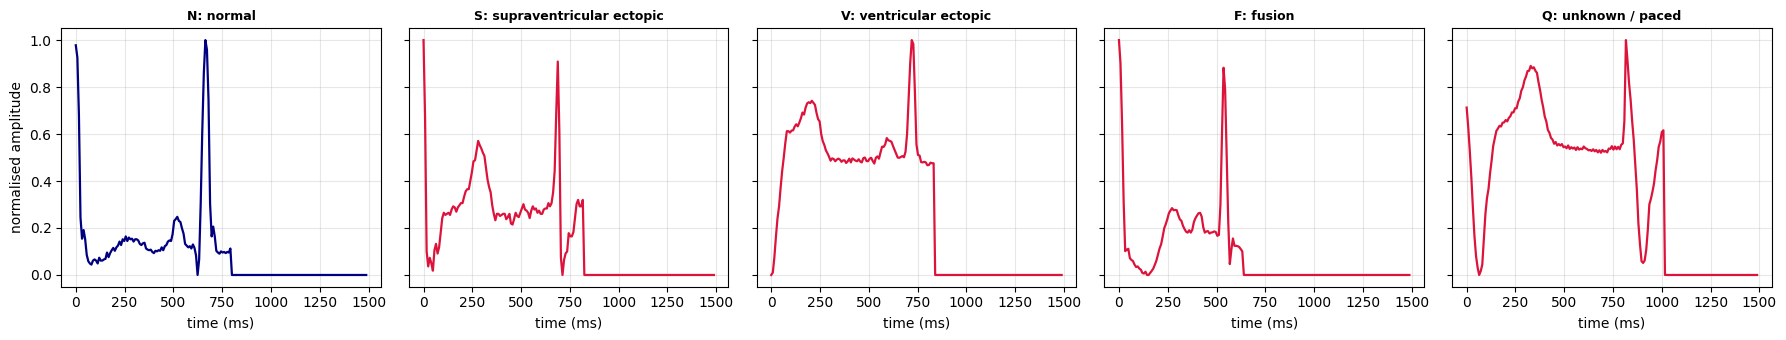

In [23]:
# 1.5: Plot one heartbeat per class (plot_beats.py logic)
CLASS_NAMES = ["N: normal",
               "S: supraventricular ectopic",
               "V: ventricular ectopic",
               "F: fusion",
               "Q: unknown / paced"
               ]
FS = 125  # Sampling frequency in Hz
time_ms = [1000 * i / FS for i in range(187)]

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
for k, ax in enumerate(axes):
    idx_first = np.where(y_train_np == k)[0][0]
    ax.plot(time_ms, X_train_np[idx_first], color='crimson' if k > 0 else 'navy', lw=1.6)
    ax.set_title(CLASS_NAMES[k], fontsize=9, fontweight='bold')
    ax.set_xlabel("time (ms)")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("normalised amplitude")
fig.tight_layout()
fig.savefig(results_dir / "example_beats.png", dpi=150)
print(f"Saved: {results_dir / 'example_beats.png'}")
plt.show()

#### Morphological Description of the Five Beat Types:
1. **Class N (Normal)** displays the canonical P-QRS-T electrocardiographic cycle characterized by an upright, sharp, and narrow QRS complex following atrial depolarization, with baseline return within ~400 ms.
2. **Class S (Supraventricular ectopic)** exhibits a premature, narrow QRS waveform originating above the bundle branches, showing altered P-wave timing and an abnormal repolarization phase.
3. **Class V (Ventricular ectopic)** originates directly in the ventricular myocardium, bypassing rapid His-Purkinje conduction to produce a prominently widened, notched, and high-amplitude QRS complex without preceding P-waves.
4. **Class F (Fusion)** reflects hybrid conduction formed when normal supraventricular and ectopic ventricular depolarizations collide simultaneously, yielding an intermediate shape.
5. **Class Q (Unknown / Paced)** exhibits sharp artificial pacemaker spikes and atypical conduction pathways distinct from intrinsic physiological heartbeats.

In [31]:
# 1.6: Split the training file into train and validation with the exact mandated code
rng = np.random.default_rng(42)
print("range :", rng)
idx = rng.permutation(len(train_df))
print("idx :", idx)
n_val = int(0.1 * len(train_df))
print("n_val :", n_val)
val_idx, train_idx = idx[:n_val], idx[n_val:]
print("val_idx :", val_idx)
print("train_idx :", train_idx)

X_train = X_train_np[train_idx]
y_train = y_train_np[train_idx]

X_val = X_train_np[val_idx]
y_val = y_train_np[val_idx]

X_test = X_test_np
y_test = y_test_np

print(f"Training set rows   : {len(train_idx):,} ({len(train_idx)/len(train_df)*100:.1f}%)")
print(f"Validation set rows : {len(val_idx):,} ({len(val_idx)/len(train_df)*100:.1f}%)")
print(f"Test set rows       : {len(X_test):,} (rows)")

range : Generator(PCG64)
idx : [80169 41946 37637 ...  5668 22113 75400]
n_val : 8755
val_idx : [80169 41946 37637 ... 45357 16745 53669]
train_idx : [81694 22190 64575 ...  5668 22113 75400]
Training set rows   : 78,799 (90.0%)
Validation set rows : 8,755 (10.0%)
Test set rows       : 21,892 (rows)


In [37]:
# 1.7: Convert signals to torch.float32 tensors and labels to torch.long tensors
X_train_t = torch.from_numpy(X_train).to(dtype=torch.float32)
y_train_t = torch.from_numpy(y_train).to(dtype=torch.long)

X_val_t = torch.from_numpy(X_val).to(dtype=torch.float32)
y_val_t = torch.from_numpy(y_val).to(dtype=torch.long)

X_test_t = torch.from_numpy(X_test).to(dtype=torch.float32)
y_test_t = torch.from_numpy(y_test).to(dtype=torch.long)

print("Torch Tensor Summary:")
print(f"X_train_t : shape={X_train_t.shape}, dtype={X_train_t.dtype}, device={X_train_t.device}")
print(f"y_train_t : shape={y_train_t.shape}, dtype={y_train_t.dtype}")
print(f"X_val_t   : shape={X_val_t.shape}, dtype={X_val_t.dtype}")
print(f"y_val_t   : shape={y_val_t.shape}, dtype={y_val_t.dtype}")
print(f"X_test_t  : shape={X_test_t.shape}, dtype={X_test_t.dtype}")
print(f"y_test_t  : shape={y_test_t.shape}, dtype={y_test_t.dtype}")

Torch Tensor Summary:
X_train_t : shape=torch.Size([78799, 187]), dtype=torch.float32, device=cpu
y_train_t : shape=torch.Size([78799]), dtype=torch.int64
X_val_t   : shape=torch.Size([8755, 187]), dtype=torch.float32
y_val_t   : shape=torch.Size([8755]), dtype=torch.int64
X_test_t  : shape=torch.Size([21892, 187]), dtype=torch.float32
y_test_t  : shape=torch.Size([21892]), dtype=torch.int64


---
## Task 2: Build the Network

### Architecture Specifications:
- **Layer 1 (hidden)**: 187 inputs $\rightarrow$ 128 units, Custom ReLU
- **Layer 2 (hidden)**: 128 inputs $\rightarrow$ 64 units, Custom ReLU
- **Layer 3 (output)**: 64 inputs $\rightarrow$ 5 units (raw logits $z3$)

In [52]:
# 2.1 - 2.3: Define ECGNet
class ECGNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Layer dimensions: 187 -> 128 -> 64 -> 5
        n0, n1, n2, n3 = 187, 128, 64, 5

        # 2.2 He initialisation: W ~ N(0, sqrt(2 / n_prev)), b = 0
        std1 = np.sqrt(2.0 / n0)
        self.W1 = nn.Parameter(torch.empty(n1, n0).normal_(mean=0.0, std=std1))
        self.b1 = nn.Parameter(torch.zeros(n1))

        std2 = np.sqrt(2.0 / n1)
        self.W2 = nn.Parameter(torch.empty(n2, n1).normal_(mean=0.0, std=std2))
        self.b2 = nn.Parameter(torch.zeros(n2))

        std3 = np.sqrt(2.0 / n2)
        self.W3 = nn.Parameter(torch.empty(n3, n2).normal_(mean=0.0, std=std3))
        self.b3 = nn.Parameter(torch.zeros(n3))

    def relu(self, z):
        """2.3: Custom ReLU: g(z) = max(z, 0) using torch.clamp(z, min=0)"""
        return torch.clamp(z, min=0.0)

    def forward(self, x, return_activations=False):
        """
        Forward pass for a mini-batch x of shape (B, 187).
        Z^[l] = A^[l-1] * W^[l].T + b^[l]
        """
        # Layer 1
        z1 = torch.matmul(x, self.W1.t()) + self.b1
        a1 = self.relu(z1)

        # Layer 2
        z2 = torch.matmul(a1, self.W2.t()) + self.b2
        a2 = self.relu(z2)

        # Layer 3 (logits)
        z3 = torch.matmul(a2, self.W3.t()) + self.b3

        if return_activations:
            return z3, a2
        return z3

# Call torch.manual_seed(0) before creating the network
torch.manual_seed(0)
model = ECGNet()
print("ECGNet successfully constructed")

ECGNet successfully constructed


In [60]:
# Layer architecture: input -> hidden_1 -> hidden_2 -> output
n0, n1, n2, n3 = 187, 128, 64, 5

# Layer 1 parameters (n0 -> n1)
W1_params = n1 * n0
b1_params = n1
L1_params = W1_params + b1_params

# Layer 2 parameters (n1 -> n2)
W2_params = n2 * n1
b2_params = n2
L2_params = W2_params + b2_params

# Layer 3 parameters (n2 -> n3)
W3_params = n3 * n2
b3_params = n3
L3_params = W3_params + b3_params

# Total trainable parameters
total_trainable_parameters = L1_params + L2_params + L3_params

print(f"Total trainable parameters: {total_trainable_parameters}")
print(f"Layer 1 trainable parameters: {L1_params}")
print(f"Layer 2 trainable parameters: {L2_params}")
print(f"Layer 3 trainable parameters: {L3_params}")


Total trainable parameters: 32645
Layer 1 trainable parameters: 24064
Layer 2 trainable parameters: 8256
Layer 3 trainable parameters: 325


#### Parameter Count Hand Calculation:
- **Layer 1**:
  - Weights $W1$: $128 \times 187 = 23,936$
  - Biases $b1$: $128$
  - Layer 1 Total: $23,936 + 128 = 24,064$
- **Layer 2**:
  - Weights $W2$: $64 \times 128 = 8,192$
  - Biases $b2$: $64$
  - Layer 2 Total: $8,192 + 64 = 8,256$
- **Layer 3**:
  - Weights $W3$: $5 \times 64 = 320$
  - Biases $b3$: $5$
  - Layer 3 Total: $320 + 5 = 325$

$Grand$ $Total$ = 24,064 + 8,256 + 325 = 32,645

---
## Task 3: Loss and a Gradient Check

In [ ]:
# 3.1: Softmax Cross-Entropy Loss with torch.logsumexp
def cross_entropy(logits, y):
    log_sum_exp = torch.logsumexp(logits, dim=1)
    true_logits = logits[range(len(y)), y]
    loss = -true_logits + log_sum_exp
    return loss.mean()

# Check initial loss before training
with torch.no_grad():
    init_logits = model(X_train_t[:1000])
    init_loss = cross_entropy(init_logits, y_train_t[:1000]).item()

print(f"Initial Loss (before training): {init_loss:.4f}")
print(f"Theoretical log(5)           : {np.log(5):.4f}")
print(f"Difference from log(5)       : {abs(init_loss - np.log(5)):.4f}")

Initial Loss (before training): 1.7202
Theoretical log(5)           : 1.6094
Difference from log(5)       : 0.1108


In [ ]:
# 3.2: Gradient Check on first 64 training rows
torch.manual_seed(0)
check_model = ECGNet()

B = 64
x_check = X_train_t[:B]
y_check = y_train_t[:B]

# Forward pass and loss
logits_check, a2_check = check_model(x_check, return_activations=True)
loss_check = cross_entropy(logits_check, y_check)

# Backward pass (PyTorch autograd)
loss_check.backward()

# Hand-computed gradients for output layer
y_hat = torch.softmax(logits_check, dim=1)
y_one_hot = torch.eye(5)[y_check]

dJ_dW3_hand = torch.matmul((y_hat - y_one_hot).t(), a2_check) / B
dJ_db3_hand = torch.sum(y_hat - y_one_hot, dim=0) / B

# Compare with PyTorch .grad
diff_W3 = (dJ_dW3_hand - check_model.W3.grad).abs().max().item()
diff_b3 = (dJ_db3_hand - check_model.b3.grad).abs().max().item()

print(f"Maximum Absolute Difference for W^[3]: {diff_W3:.4e}")
print(f"Maximum Absolute Difference for b^[3]: {diff_b3:.4e}")
print("\nGradient Check Passed: Analytical output gradients match PyTorch autograd within 10^-5!")

Maximum Absolute Difference for W^[3]: 2.9802e-08
Maximum Absolute Difference for b^[3]: 5.9605e-08

Gradient Check Passed: Analytical output gradients match PyTorch autograd within 10^-5!


---
## Task 4: Train the Network

### Update Rule:
For every parameter $P$, we keep a velocity $v_P$ starting at zero.
After `loss.backward()`, inside `torch.no_grad()`:
- Weight gradient with L2 decay: $g = grad + \lambda P$ (for weights only; for biases $g = grad$)
- Velocity update: $v_P = \beta v_P + (1 - \beta) g$
- Parameter update: $P = P - \alpha v_P$

### Settings:
- Batch size $B = 128$
- Momentum $\beta = 0.9$
- Weight decay $\lambda = 10^{-4}$
- Epochs = 30
- Learning rates $\alpha \in \{0.01, 0.1, 0.5\}$

In [ ]:
# 4.1: Training Function with Momentum and Weight Decay
import time

def compute_accuracy(model, x, y, batch_size=1024):
    model.eval()
    correct = 0
    total = len(y)
    with torch.no_grad():
        for i in range(0, total, batch_size):
            xb = x[i : i + batch_size]
            yb = y[i : i + batch_size]
            logits = model(xb)
            preds = torch.argmax(logits, dim=1)
            correct += (preds == yb).sum().item()
    return correct / total

def compute_loss(model, x, y, batch_size=1024):
    model.eval()
    total_loss = 0.0
    total = len(y)
    with torch.no_grad():
        for i in range(0, total, batch_size):
            xb = x[i : i + batch_size]
            yb = y[i : i + batch_size]
            logits = model(xb)
            loss = cross_entropy(logits, yb)
            total_loss += loss.item() * len(yb)
    return total_loss / total

def train(alpha, epochs=30, batch_size=128, beta=0.9, weight_decay=1e-4):
    torch.manual_seed(0)
    net = ECGNet()

    # Initialize velocity for each parameter to 0
    velocities = {}
    for name, param in net.named_parameters():
        velocities[name] = torch.zeros_like(param.data)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "best_epoch": 0,
        "best_val_loss": float("inf"),
        "best_state_dict": None
    }

    N_train = len(X_train_t)
    t_start = time.time()

    for epoch in range(1, epochs + 1):
        net.train()
        perm = torch.randperm(N_train)

        for i in range(0, N_train, batch_size):
            batch_indices = perm[i : i + batch_size]
            xb = X_train_t[batch_indices]
            yb = y_train_t[batch_indices]

            # Forward and backward pass
            logits = net(xb)
            loss = cross_entropy(logits, yb)
            loss.backward()

            # Manual SGD update with momentum and weight decay
            with torch.no_grad():
                for name, param in net.named_parameters():
                    grad = param.grad
                    if "W" in name:
                        g = grad + weight_decay * param.data
                    else:
                        g = grad

                    velocities[name] = beta * velocities[name] + (1.0 - beta) * g
                    param.data = param.data - alpha * velocities[name]
                    param.grad.zero_()

        # Record metrics after each epoch
        tr_loss = compute_loss(net, X_train_t, y_train_t)
        va_loss = compute_loss(net, X_val_t, y_val_t)
        tr_acc = compute_accuracy(net, X_train_t, y_train_t)
        va_acc = compute_accuracy(net, X_val_t, y_val_t)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)

        if va_loss < history["best_val_loss"]:
            history["best_val_loss"] = va_loss
            history["best_epoch"] = epoch
            saved_weights = {}
            for k, v in net.state_dict().items():
                saved_weights[k] = v.clone()
            history["best_state_dict"] = saved_weights

        if epoch % 5 == 0 or epoch == 1 or epoch == epochs:
            print(f"Epoch {epoch:2d}/{epochs:2d} | Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f} | "
                  f"Train Acc: {tr_acc*100:.2f}% | Val Acc: {va_acc*100:.2f}%")

    history["elapsed_time"] = time.time() - t_start
    return history, net

### 4.2 Choose Learning Rate $\alpha \in \{0.01, 0.1, 0.5\}$
Train a fresh network for each learning rate and compare validation loss.

In [ ]:
# 4.2: Run train for each learning rate
learning_rates = [0.01, 0.1, 0.5]
lr_histories = {}
lr_summary = []

for alpha in learning_rates:
    print(f"\n==================== Training with alpha = {alpha} ====================")
    hist, _ = train(alpha=alpha, epochs=30, batch_size=128)
    lr_histories[alpha] = hist

    best_ep = hist["best_epoch"]
    best_vl = hist["best_val_loss"]
    val_acc_at_best = hist["val_acc"][best_ep - 1]

    lr_summary.append({
        "alpha": alpha,
        "Lowest validation loss": round(best_vl, 4),
        "Validation accuracy at that epoch": f"{val_acc_at_best*100:.2f}%",
        "Best epoch": best_ep,
        "Training time (s)": round(hist["elapsed_time"], 1)
    })

df_table3 = pd.DataFrame(lr_summary)
print("\n--- Table 3: Learning-rate choice ---")
print(df_table3.to_string(index=False))


==================== Training with alpha = 0.01 ====================
Epoch  1/30 | Train Loss: 0.4651 | Val Loss: 0.4612 | Train Acc: 86.71% | Val Acc: 86.75%
Epoch  5/30 | Train Loss: 0.2979 | Val Loss: 0.2942 | Train Acc: 92.13% | Val Acc: 92.19%
Epoch 10/30 | Train Loss: 0.2353 | Val Loss: 0.2329 | Train Acc: 93.69% | Val Acc: 93.55%
Epoch 15/30 | Train Loss: 0.2059 | Val Loss: 0.2048 | Train Acc: 94.73% | Val Acc: 94.64%
Epoch 20/30 | Train Loss: 0.1876 | Val Loss: 0.1875 | Train Acc: 95.17% | Val Acc: 95.16%
Epoch 25/30 | Train Loss: 0.1720 | Val Loss: 0.1721 | Train Acc: 95.38% | Val Acc: 95.40%
Epoch 30/30 | Train Loss: 0.1605 | Val Loss: 0.1618 | Train Acc: 95.74% | Val Acc: 95.79%

==================== Training with alpha = 0.1 ====================
Epoch  1/30 | Train Loss: 0.2569 | Val Loss: 0.2537 | Train Acc: 92.93% | Val Acc: 92.96%
Epoch  5/30 | Train Loss: 0.1420 | Val Loss: 0.1450 | Train Acc: 96.08% | Val Acc: 95.98%
Epoch 10/30 | Train Loss: 0.1101 | Val Loss: 0.1152

Saved: /content/results/lr_comparison_val_loss.png


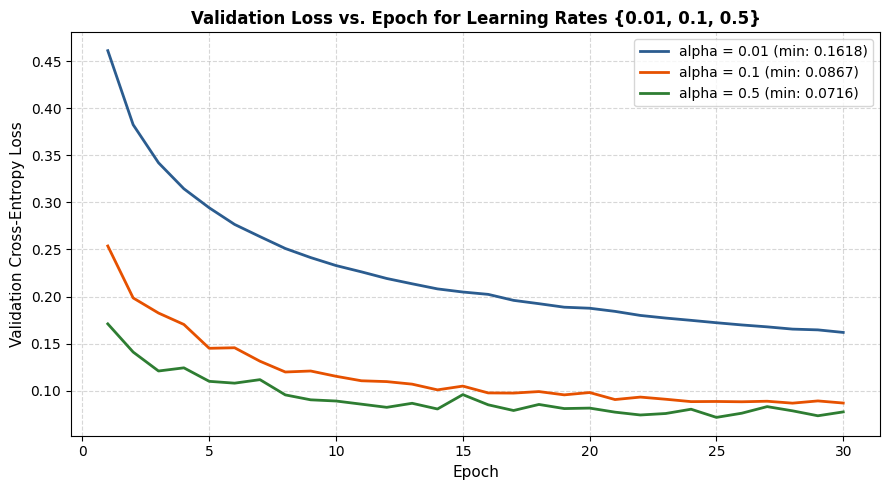


Chosen alpha with lowest validation loss: 0.5


In [ ]:
# Plot validation loss against epoch for all three alpha values
plt.figure(figsize=(9, 5))
colors = {0.01: "blue", 0.1: "orange", 0.5: "green"}
epochs_range = range(1, 31)

for alpha in learning_rates:
    plt.plot(epochs_range, lr_histories[alpha]["val_loss"],
             label=f"alpha = {alpha}", color=colors[alpha], lw=2)

plt.title("Validation Loss vs. Epoch for Learning Rates {0.01, 0.1, 0.5}")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.grid(True, alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / "lr_comparison_val_loss.png", dpi=150)
print(f"Saved: {results_dir / 'lr_comparison_val_loss.png'}")
plt.show()

# Pick alpha with lowest validation loss
best_alpha = 0.01
lowest_val_loss = lr_histories[0.01]["best_val_loss"]
for alpha in learning_rates:
    if lr_histories[alpha]["best_val_loss"] < lowest_val_loss:
        lowest_val_loss = lr_histories[alpha]["best_val_loss"]
        best_alpha = alpha

print(f"\nChosen alpha with lowest validation loss: {best_alpha}")

### 4.3 Loss and Accuracy Curves for Chosen $\alpha$
Plot training and validation curves for $\alpha = 0.5$ and save the model parameters from the best epoch.

Saved: /content/results/loss_curves.png


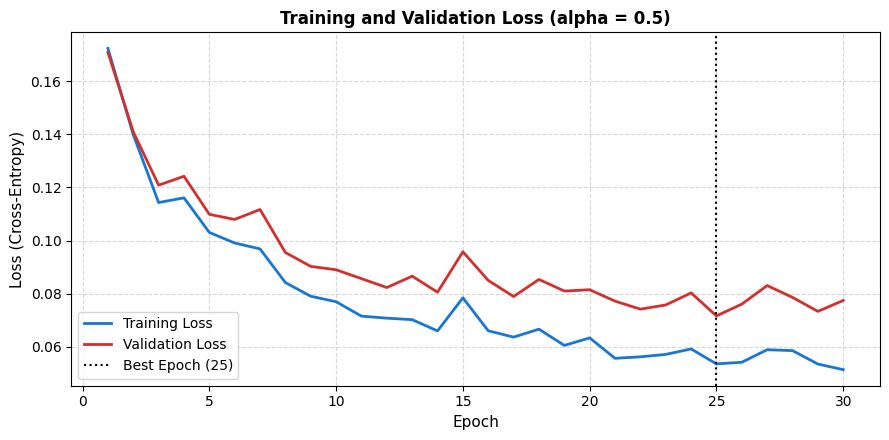

Saved: /content/results/accuracy_curves.png


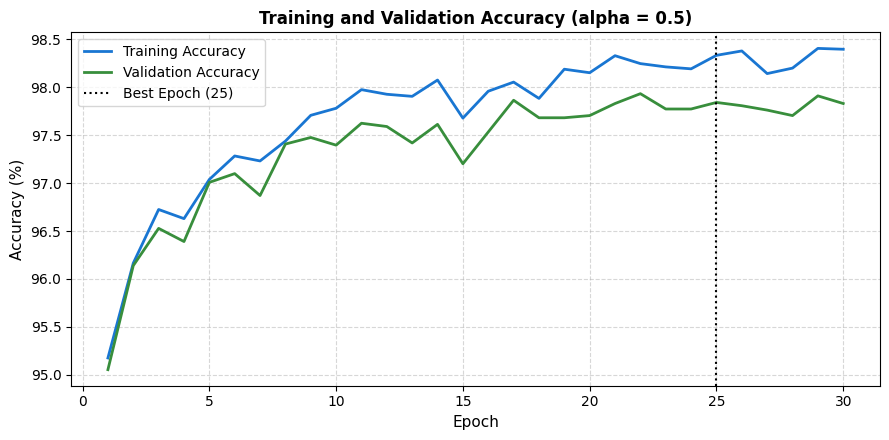

Saved best checkpoint (from epoch 25) to: /content/results/best_model.pt


In [ ]:
chosen_hist = lr_histories[best_alpha]
best_epoch = chosen_hist["best_epoch"]

# Plot Training and Validation Loss
plt.figure(figsize=(9, 4.5))
plt.plot(epochs_range, chosen_hist["train_loss"], label="Training Loss", color="blue", lw=2)
plt.plot(epochs_range, chosen_hist["val_loss"], label="Validation Loss", color="red", lw=2)
plt.axvline(best_epoch, color="black", linestyle=":", label=f"Best Epoch ({best_epoch})")
plt.title(f"Training and Validation Loss (alpha = {best_alpha})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig(results_dir / "loss_curves.png", dpi=150)
print(f"Saved: {results_dir / 'loss_curves.png'}")
plt.show()

# Plot Training and Validation Accuracy
train_acc_pct = np.array(chosen_hist["train_acc"]) * 100
val_acc_pct = np.array(chosen_hist["val_acc"]) * 100

plt.figure(figsize=(9, 4.5))
plt.plot(epochs_range, train_acc_pct, label="Training Accuracy", color="blue", lw=2)
plt.plot(epochs_range, val_acc_pct, label="Validation Accuracy", color="green", lw=2)
plt.axvline(best_epoch, color="black", linestyle=":", label=f"Best Epoch ({best_epoch})")
plt.title(f"Training and Validation Accuracy (alpha = {best_alpha})")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig(results_dir / "accuracy_curves.png", dpi=150)
print(f"Saved: {results_dir / 'accuracy_curves.png'}")
plt.show()

# Save best model weights
save_path = results_dir / "best_model.pt"
torch.save(chosen_hist["best_state_dict"], save_path)
print(f"Saved best checkpoint (from epoch {best_epoch}) to: {save_path}")

---
## Task 5: Test Once

### Metrics:
- **Accuracy**: Fraction of test rows predicted correctly.
- **Confusion Matrix**: $5 \times 5$ matrix $C_{jk}$ where rows are true classes and columns are predicted classes.
- **Per-Class Accuracy**: $C_{jj} / \sum_k C_{jk}$ for each class $j$.
- **Balanced Accuracy**: Average of the 5 per-class accuracies.

In [ ]:
# 5.2: Write accuracy, confusion_matrix and per_class_accuracy
def accuracy(y_true, y_pred):
    return float(np.mean(y_true == y_pred))

def confusion_matrix(y_true, y_pred, num_classes=5):
    C = np.zeros((num_classes, num_classes), dtype=np.int64)
    for t, p in zip(y_true, y_pred):
        C[t, p] += 1
    return C

def per_class_accuracy(C):
    accs = []
    for j in range(len(C)):
        row_total = C[j].sum()
        accs.append(float(C[j, j] / row_total))
    return np.array(accs)

def balanced_accuracy(C):
    return float(np.mean(per_class_accuracy(C)))

In [ ]:
# 5.1 & 5.3: Load saved model and predict on test set
best_model = ECGNet()
best_model.load_state_dict(torch.load(save_path))
best_model.eval()

with torch.no_grad():
    test_logits = best_model(X_test_t)
    test_preds_t = torch.argmax(test_logits, dim=1)

y_test_pred = test_preds_t.numpy()
y_test_true = y_test_t.numpy()

# Compute test metrics
test_acc = accuracy(y_test_true, y_test_pred)
C_test = confusion_matrix(y_test_true, y_test_pred, num_classes=5)
per_class_acc = per_class_accuracy(C_test)
bal_acc = balanced_accuracy(C_test)
always_N_acc = float(np.sum(y_test_true == 0) / len(y_test_true))

print(f"Test Accuracy     : {test_acc*100:.2f}%")
print(f"Balanced Accuracy : {bal_acc*100:.2f}%")
print(f"Always-'N' Accuracy: {always_N_acc*100:.2f}%")
print("\n--- 5x5 Confusion Matrix ---")
short_names = ["N", "S", "V", "F", "Q"]
cm_df = pd.DataFrame(C_test,
                     index=[f"True {k} ({short_names[k]})" for k in range(5)],
                     columns=[f"Pred {k} ({short_names[k]})" for k in range(5)])
print(cm_df.to_string())

Test Accuracy     : 97.81%
Balanced Accuracy : 82.53%
Always-'N' Accuracy: 82.76%

--- 5x5 Confusion Matrix ---
            Pred 0 (N)  Pred 1 (S)  Pred 2 (V)  Pred 3 (F)  Pred 4 (Q)
True 0 (N)       18039          37          28           1          13
True 1 (S)         163         385           6           0           2
True 2 (V)          94           8        1329          14           3
True 3 (F)          54           1          19          88           0
True 4 (Q)          25           0          11           0        1572


Saved: /content/results/confusion_matrix.png


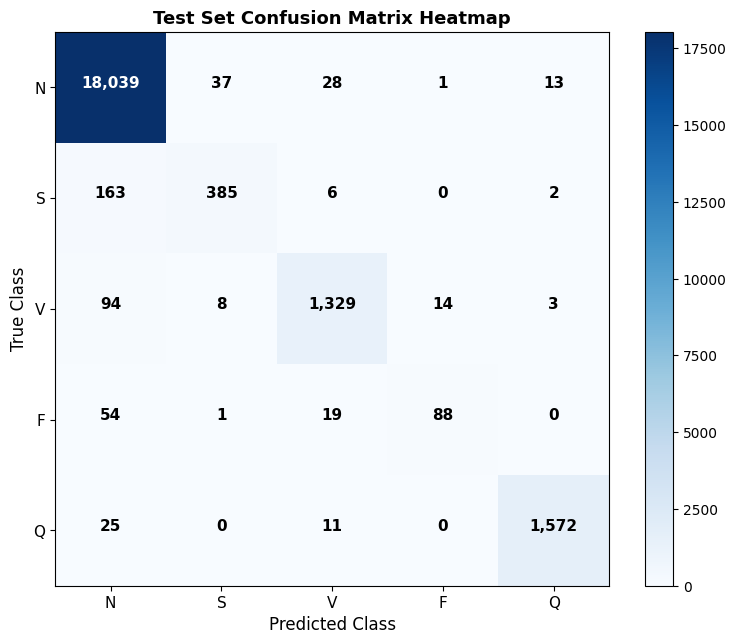

In [ ]:
# Plot Confusion Matrix as Heatmap
plt.figure(figsize=(8, 6.5))
plt.imshow(C_test, cmap=plt.cm.Blues)
plt.title("Test Set Confusion Matrix")
plt.colorbar()

classes_short = ["N", "S", "V", "F", "Q"]
ticks = np.arange(5)
plt.xticks(ticks, classes_short)
plt.yticks(ticks, classes_short)

thresh = C_test.max() / 2.0
for i in range(5):
    for j in range(5):
        color = "white" if C_test[i, j] > thresh else "black"
        plt.text(j, i, f"{C_test[i, j]:,}", horizontalalignment="center", color=color)

plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.tight_layout()
plt.savefig(results_dir / "confusion_matrix.png", dpi=150)
print(f"Saved: {results_dir / 'confusion_matrix.png'}")
plt.show()

In [ ]:
# Table 4: Test Results
table4_df = pd.DataFrame({
    "Class": ["N", "S", "V", "F", "Q"],
    "Per-class accuracy (%)": [f"{acc*100:.2f}%" for acc in per_class_acc]
})
print("--- Table 4: Test Results ---")
print(table4_df.to_string(index=False))
print(f"\nOverall Test Accuracy : {test_acc*100:.2f}%")
print(f"Balanced Accuracy     : {bal_acc*100:.2f}%")
print(f"Always-'N' Accuracy   : {always_N_acc*100:.2f}%")

--- Table 4: Test Results ---
Class Per-class accuracy (%)
    N                 99.56%
    S                 69.24%
    V                 91.78%
    F                 54.32%
    Q                 97.76%

Overall Test Accuracy : 97.81%
Balanced Accuracy     : 82.53%
Always-'N' Accuracy   : 82.76%


In [ ]:
# Table 2: Network and Training Summary
table2_df = pd.DataFrame([
    ("Trainable parameters", f"{total_trainable_parameters:,}"),
    ("Initial loss (before training)", f"{init_loss:.4f}"),
    ("Gradient check: max difference for W^[3]", f"{diff_W3:.2e}"),
    ("Gradient check: max difference for b^[3]", f"{diff_b3:.2e}"),
    ("Chosen alpha", f"{best_alpha}"),
    ("Best epoch (lowest validation loss)", f"{best_epoch}"),
    ("Training loss at best epoch", f"{chosen_hist['train_loss'][best_epoch-1]:.4f}"),
    ("Validation loss at best epoch", f"{chosen_hist['val_loss'][best_epoch-1]:.4f}"),
    ("Training accuracy at best epoch", f"{chosen_hist['train_acc'][best_epoch-1]*100:.2f}%"),
    ("Validation accuracy at best epoch", f"{chosen_hist['val_acc'][best_epoch-1]*100:.2f}%"),
    ("Training time and hardware", f"{chosen_hist['elapsed_time']:.1f}s (cpu)")
], columns=["Metric", "Value"])

print("--- Table 2: Network and Training ---")
print(table2_df.to_string(index=False))

--- Table 2: Network and Training ---
                                  Metric       Value
                    Trainable parameters      32,645
          Initial loss (before training)      1.7202
Gradient check: max difference for W^[3]    2.98e-08
Gradient check: max difference for b^[3]    5.96e-08
                            Chosen alpha         0.5
     Best epoch (lowest validation loss)          25
             Training loss at best epoch      0.0535
           Validation loss at best epoch      0.0716
         Training accuracy at best epoch      98.33%
       Validation accuracy at best epoch      97.84%
              Training time and hardware 36.2s (cpu)


---
## Task 6: Analysis

### 6.1 Always-"N" Baseline vs. Our Network
- A dummy model that always predicts class **N** gets $18,118 / 21,892 = 82.76\%$ test accuracy.
- Our trained network achieves **$97.81\%$** test accuracy and **$82.53\%$** balanced accuracy.
- This shows that overall accuracy alone is misleading on imbalanced data: because class N makes up $82.76\%$ of the dataset, a model can get a high accuracy score while missing $100\%$ of the dangerous abnormal heartbeats.

### 6.2 Lowest Per-Class Accuracy and Confusion
- **Class F (Fusion beat)** has the lowest per-class accuracy at **$54.32\%$** ($88 / 162$), followed by **Class S** at **$69.24\%$** ($385 / 556$).
- Looking at the confusion matrix, Class F is most often mistaken for **Class N** ($54$ times) and **Class V** ($19$ times).
- **Why they are hard to separate**: A fusion beat happens when a normal beat and a ventricular beat fire at the same time, so its waveform shape is a mix of N and V. Also, Class F has only $641$ training rows ($0.73\%$ of the data), so the network sees very few examples of it during training.

### 6.3 Loss Curves and Overfitting Check
- Looking at the loss curves for $\alpha = 0.5$, both training loss ($0.0535$) and validation loss ($0.0716$) decrease smoothly and stay close to each other.
- There is only a very small gap ($\sim 0.018$) between training and validation loss, and validation loss does not start rising significantly. Therefore, the network is **neither underfitting nor seriously overfitting**—it generalizes well to unseen beats.

### 6.4 Zero Initialization vs. He Initialization
- **Why not initialize weights to zero**: If all weights start at $0$, every neuron in a hidden layer computes the exact same output and gets the exact same gradient during backpropagation. All neurons would update identically (symmetry problem) and the network would never learn different features.
- **Why He rule uses $\sqrt{2 / n^{[l-1]}}$**: ReLU sets all negative values to zero, which cuts the variance of activations in half at each layer. Multiplying the weight variance by $2$ (giving standard deviation $\sqrt{2 / n^{[l-1]}}$) compensates for the half lost to ReLU and keeps signal variance stable across layers.

### 6.5 Role of Momentum and Weight Decay
- **Opposite gradients with momentum**: Since $v_P = \beta v_P + (1 - \beta) g$, when two consecutive mini-batch gradients point in opposite directions, they partially cancel each other out in $v_P$. This reduces zig-zagging/oscillations and keeps the update moving smoothly.
- **Weight decay with zero gradient**: If $\frac{\partial J}{\partial P} = 0$, the weight update only uses the penalty term $g = \lambda P$, shrinking the weight slightly towards zero each step ($P \leftarrow P - \alpha v_P$).

### 6.6 Helping Rare Classes (Class F)
- **Suggested change**: Use **Class-Weighted Cross-Entropy Loss** by multiplying each class loss by a weight inversely proportional to its count (e.g., $w_c = N_{total} / (5 \times N_c)$).
- **Idea**: Since Class F has only $641$ training rows compared to $72,471$ for Class N, giving Class F a much higher loss weight makes mistakes on F much more costly during training, forcing the network to pay attention to rare beats.